# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

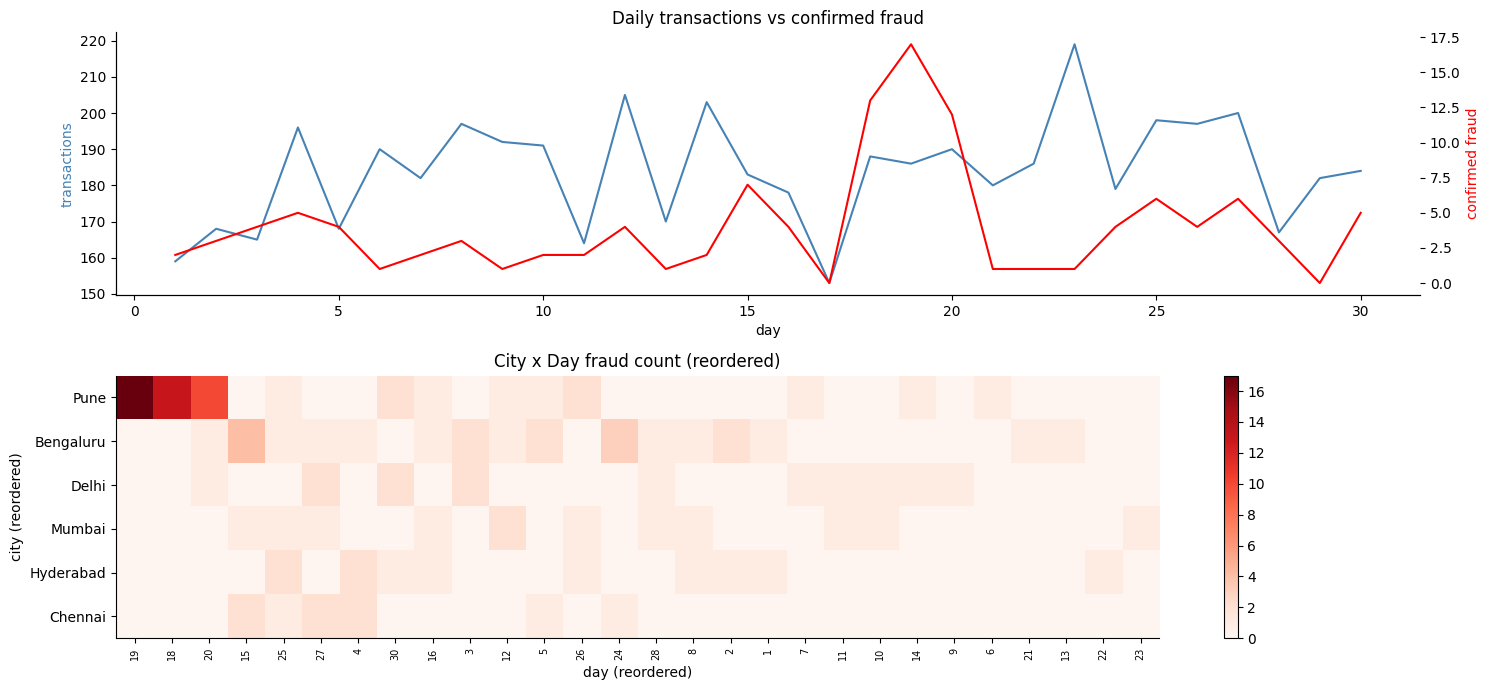

Highest-fraud (city, day) cells:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
dtype: int64


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily_count = tx.groupby("day").size()
daily_fraud = tx.groupby("day")["is_fraud"].sum()
axes[0].plot(daily_count.index, daily_count.values, color="steelblue", label="transactions")
ax2 = axes[0].twinx()
ax2.plot(daily_fraud.index, daily_fraud.values, color="red", label="confirmed fraud")
axes[0].set_xlabel("day"); axes[0].set_ylabel("transactions", color="steelblue")
ax2.set_ylabel("confirmed fraud", color="red")
axes[0].set_title("Daily transactions vs confirmed fraud")

# TODO 2
heat = tx[tx.is_fraud == 1].pivot_table(index="city", columns="day", values="txn_id", aggfunc="count", fill_value=0)
row_order = heat.sum(axis=1).sort_values(ascending=False).index
col_order = heat.sum(axis=0).sort_values(ascending=False).index
heat = heat.loc[row_order, col_order]
im = axes[1].imshow(heat.values, aspect="auto", cmap="Reds")
axes[1].set_yticks(range(len(heat.index))); axes[1].set_yticklabels(heat.index)
axes[1].set_xticks(range(len(heat.columns))); axes[1].set_xticklabels(heat.columns, rotation=90, fontsize=7)
axes[1].set_xlabel("day (reordered)"); axes[1].set_ylabel("city (reordered)")
axes[1].set_title("City x Day fraud count (reordered)")
plt.colorbar(im, ax=axes[1])

plt.tight_layout(); plt.show()

# TODO 3
top_cells = heat.stack().sort_values(ascending=False).head(5)
print("Highest-fraud (city, day) cells:")
print(top_cells)

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
A sorted alert list only shows individual transactions ranked by score, it wouldn't tell you that fraud is clustering heavily in one city over a few consecutive days - Pune around days 18-20 basically jumps out in the heatmap once the rows/cols are reordered by total. An alert list buries that pattern because the rows aren't grouped by city or day at all, you'd have to manually scroll through hundreds of alerts and notice the city names repeating. This is the "reordering reveals structure" idea from the lecture - putting high-activity rows/cols next to each other makes the cluster visually pop out instead of being scattered through the data.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

/tmp/ipykernel_2048/3634464725.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(cat_all.index, rotation=90)
/tmp/ipykernel_2048/3634464725.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(city_all.index, rotation=90)


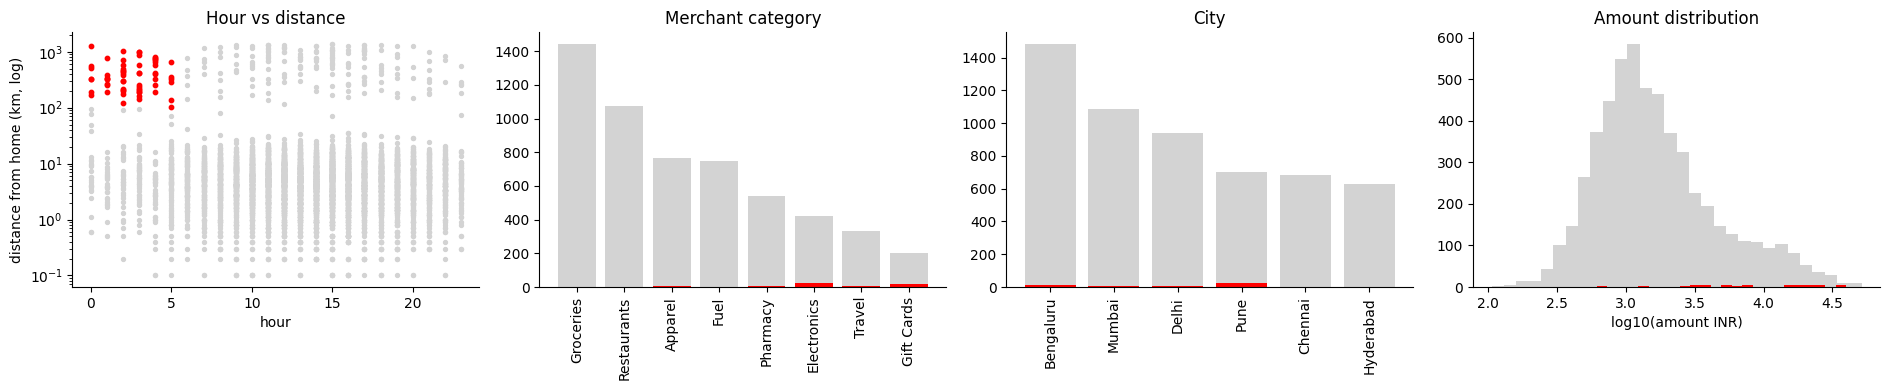

brushed: 61 txns | fraud rate in brush: 86.9% vs overall: 2.2%
share of ALL fraud captured by this brush: 44.2%


In [3]:
# TODO 1
brush = (tx.night == True) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
axes[0].scatter(tx.hour[~brush], tx.distance_from_home_km[~brush], s=8, color="lightgrey")
axes[0].scatter(tx.hour[brush], tx.distance_from_home_km[brush], s=10, color="red")
axes[0].set_yscale("log"); axes[0].set_xlabel("hour"); axes[0].set_ylabel("distance from home (km, log)")
axes[0].set_title("Hour vs distance")

cat_all = tx.merchant_category.value_counts()
cat_brush = tx.merchant_category[brush].value_counts().reindex(cat_all.index, fill_value=0)
axes[1].bar(cat_all.index, cat_all.values, color="lightgrey")
axes[1].bar(cat_brush.index, cat_brush.values, color="red")
axes[1].set_xticklabels(cat_all.index, rotation=90)
axes[1].set_title("Merchant category")

city_all = tx.city.value_counts()
city_brush = tx.city[brush].value_counts().reindex(city_all.index, fill_value=0)
axes[2].bar(city_all.index, city_all.values, color="lightgrey")
axes[2].bar(city_brush.index, city_brush.values, color="red")
axes[2].set_xticklabels(city_all.index, rotation=90)
axes[2].set_title("City")

axes[3].hist(np.log10(tx.amount_inr), bins=30, color="lightgrey")
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=30, color="red")
axes[3].set_xlabel("log10(amount INR)")
axes[3].set_title("Amount distribution")

plt.tight_layout(); plt.show()

# TODO 3
n_brushed = brush.sum()
fraud_rate_brush = tx.loc[brush, "is_fraud"].mean()
fraud_rate_overall = tx["is_fraud"].mean()
share_captured = tx.loc[brush, "is_fraud"].sum() / tx["is_fraud"].sum()
print(f"brushed: {n_brushed} txns | fraud rate in brush: {fraud_rate_brush:.1%} vs overall: {fraud_rate_overall:.1%}")
print(f"share of ALL fraud captured by this brush: {share_captured:.1%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_
The brush rate is like 87% fraud which sounds amazing, but it only captures around 44% of all fraud in the dataset - so more than half the fraud cases are happening outside the night+far-from-home rule. This tells the investigators that "night time far from home" is a very precise rule (almost everything it flags really is fraud) but its not a complete rule - if they only rely on this they'll miss over half the fraud cases. The city bar chart hinted where the rest might be - a lot of the fraud count was concentrated in Pune which doesnt obviously line up with just night/distance, so theres probably another pattern (the city/day cluster from task1) driving the rest of it.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = 50_000_000 * (best_s / len(big))
skip_pct = (1 - max_rows / 50_000_000) * 100

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 17.0 ms -> 0.0169 us/row -> max 5,925,354 rows in 0.1 s
50M rows -> 0.84 s; must skip 88.1% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
Sampling - instead of filtering across all 50 million rows live, you could draw a representative random sample (like 1-2 million rows) and run the filter on that subsample, then scale the result up. It would keep the slider feeling instant because the per-item cost stays the same but now theres way fewer items. What you lose is exactness - rare patterns (like a very specific tiny cluster of fraud in one city on one day, which is basically what we found in task1/task6) might get missed entirely or their counts estimated wrong if they fall below the sampling rate, so you'd be trading precision for speed.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

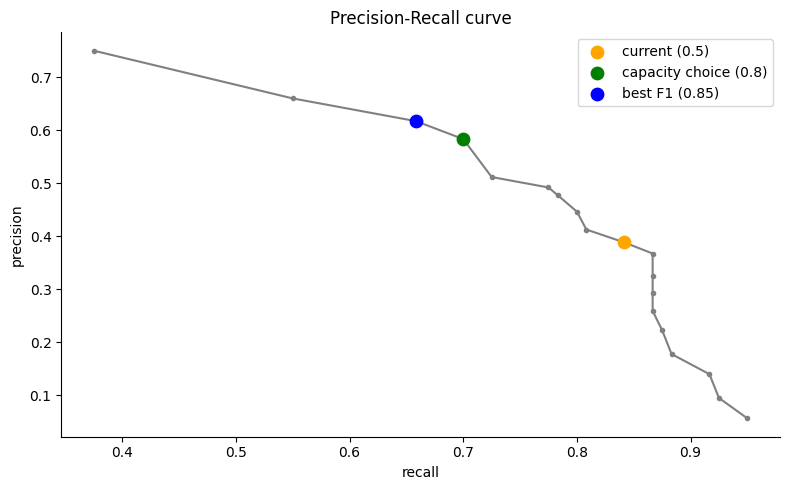

Recommendation: move threshold from 0.5 to 0.8 to stay within the 150-alert/month capacity while keeping recall as high as possible (70.0%).


In [5]:
rows = []
# TODO 1
for th in np.arange(0.05, 0.951, 0.05):
    th = round(th, 2)
    flagged = tx.detector_score >= th
    tp = int(((flagged) & (tx.is_fraud == 1)).sum())
    fp = int(((flagged) & (tx.is_fraud == 0)).sum())
    fn = int(((~flagged) & (tx.is_fraud == 1)).sum())
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    rows.append(dict(threshold=th, alerts=int(flagged.sum()), TP=tp, FP=fp, FN=fn,
                      precision=precision, recall=recall, f1=f1))

pr = pd.DataFrame(rows)

# TODO 2
under_cap = pr[pr.alerts <= 150]
capacity_choice = under_cap.loc[under_cap.recall.idxmax(), "threshold"]
best_f1 = pr.loc[pr.f1.idxmax(), "threshold"]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", ms=3, color="grey")
cur = pr[pr.threshold == 0.5].iloc[0]
cap = pr[pr.threshold == capacity_choice].iloc[0]
f1r = pr[pr.threshold == best_f1].iloc[0]
ax.scatter(cur.recall, cur.precision, color="orange", s=80, label=f"current (0.5)", zorder=5)
ax.scatter(cap.recall, cap.precision, color="green", s=80, label=f"capacity choice ({capacity_choice})", zorder=5)
ax.scatter(f1r.recall, f1r.precision, color="blue", s=80, label=f"best F1 ({best_f1})", zorder=5)
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-Recall curve")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: move threshold from 0.5 to {capacity_choice} to stay within the 150-alert/month capacity "
      f"while keeping recall as high as possible ({cap.recall:.1%}).")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The Head of Fraud Ops should make the final call, not the model, because the model only knows about precision/recall numbers - it has no idea that the team can physically only review 150 cases a month. The best-F1 point is a purely statistical optimum, it doesnt care about staffing or operational limits at all. The lecture pushes human-in-the-loop here because the "right" threshold depends on a business constraint (review capacity) that only a person managing the team actually knows, so the visualization's job is just to lay out the tradeoff clearly (the PR curve) and let the manager pick the point that fits their real-world limits, rather than the system silently deciding for them.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3].copy()

fig1 = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
    hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
    title="Flagged transactions (score >= 0.3)"
)
fig1.update_layout(dragmode="select")
fig1.show()

# TODO 2
sun = tx.groupby(["city", "merchant_category"]).agg(count=("txn_id", "count"), fraud_rate=("is_fraud", "mean")).reset_index()
fig2 = px.sunburst(
    sun, path=["city", "merchant_category"], values="count", color="fraud_rate",
    color_continuous_scale="Reds", title="City -> Category drill-down (color = fraud rate)"
)
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_
Tooltips only show details for one point when you hover over it, so if an investigator wanted to understand the whole batch of ~400 flagged cases they'd have to hover over each dot one at a time which just isn't practical - thats 400 individual hovers and your working memory cant hold all that info together anyway. The heatmap from Task 1 (and really the sunburst drill down too) fixes this because it shows the aggregate pattern across everything at once - you see where the concentration is immediately instead of piecing it together point by point.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

is_fraud     0   1
row_0             
False     5333  80
True        67  40
chi2 = 619.29, p-value = 1.065e-136
window: 37.4% | Pune other days: 1.9% | other cities same days: 0.4% | rest: 1.5%


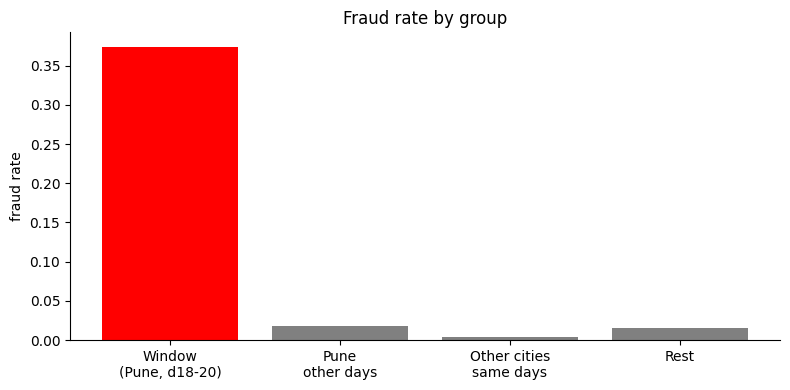

Verdict: fraud rate inside the window is dramatically higher than every counter-example group (both other days in Pune AND other cities on the same days), and the chi-square p-value is essentially 0, so this is NOT just a city effect or a day effect on their own - it really does look like a localized fraud ring specific to Pune during days 18-20.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
# (from Task 1 overview: Pune, days ~18-20 stood out as the fraud hotspot)
in_window = (tx.city == "Pune") & (tx.day.between(18, 20))

# TODO 2
ct_table = pd.crosstab(in_window, tx.is_fraud)
chi2, p_value, dof, expected = chi2_contingency(ct_table)
print(ct_table)
print(f"chi2 = {chi2:.2f}, p-value = {p_value:.3e}")

# TODO 3
fr_window = tx.loc[in_window, "is_fraud"].mean()
fr_city_other_days = tx.loc[(tx.city == "Pune") & ~tx.day.between(18, 20), "is_fraud"].mean()
fr_other_cities_same_days = tx.loc[(tx.city != "Pune") & tx.day.between(18, 20), "is_fraud"].mean()
fr_rest = tx.loc[~in_window & ~((tx.city == "Pune") | tx.day.between(18, 20)), "is_fraud"].mean()

print(f"window: {fr_window:.1%} | Pune other days: {fr_city_other_days:.1%} | "
      f"other cities same days: {fr_other_cities_same_days:.1%} | rest: {fr_rest:.1%}")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
groups = ["Window\n(Pune, d18-20)", "Pune\nother days", "Other cities\nsame days", "Rest"]
vals = [fr_window, fr_city_other_days, fr_other_cities_same_days, fr_rest]
ax.bar(groups, vals, color=["red", "grey", "grey", "grey"])
ax.set_ylabel("fraud rate"); ax.set_title("Fraud rate by group")
plt.tight_layout(); plt.show()

# TODO 5
print("Verdict: fraud rate inside the window is dramatically higher than every counter-example group "
      "(both other days in Pune AND other cities on the same days), and the chi-square p-value is essentially 0, "
      "so this is NOT just a city effect or a day effect on their own - it really does look like a localized "
      "fraud ring specific to Pune during days 18-20.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_
If "Pune other days" had shown a high fraud rate too (similar to the window), that would've killed the city-ring idea and pointed to Pune just being a generally high-fraud city all the time, not a ring tied to those specific days. If instead "other cities same days" had shown a high rate, that would mean something was happening nation-wide in that date range (like a holiday weekend or a bigger campaign-level attack) rather than being localized to one city, so it would've supported a time-based explanation instead of a city-based one. Since neither counter-example came back high, both alternative explanations are ruled out and the city+day combo really does look specific.

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_
Last month saw a clear fraud spike concentrated in Pune on days 18-20, with a fraud rate of about 37% in that window vs under 2% everywhere else - this is confirmed statistically (chi-square p basically 0) and looks like a localized fraud ring rather than noise. I'd recommend moving the alert threshold from 0.5 to around 0.80, since that's the highest-recall option that still keeps us inside the 150 alerts/month review capacity - this is a judgement call for you to make rather than letting the model auto-pick the best-F1 point, because only you know the team's actual review bandwidth. For the investigators I'd build the interactive scatter + sunburst view first, since it gives details-on-demand (hover for the full transaction) on top of an overview-first layout, which beats a static alert list for spotting patterns quickly. Going forward we should set up a feedback loop where investigator-confirmed labels from this month get fed back into retraining the detector, so it adapts to new fraud patterns like the Pune cluster instead of using a static model.